In [51]:
# import pandas as pd
import pandas as pd
import numpy as np

Loading the Data set 

In [52]:
sessions = pd.read_csv("datasets/stadiochoice/table1_trial_viewer_behaviour.csv")
billing = pd.read_csv("datasets/stadiochoice/table2_subscription_billing.csv")
outcome = pd.read_csv("datasets/stadiochoice/table3_conversion_outcome.csv")
demographics = pd.read_csv("datasets/stadiochoice/table4_trial_user_demographics.csv")


In [53]:
# Inspect the sessions  data set
print("sessions shape:", sessions.shape)
print("sessions duplicate count:", sessions.duplicated().sum())
print("sessions head:")
display(sessions.head())

sessions shape: (123470, 12)
sessions duplicate count: 369
sessions head:


,account_id,session_id,session_start,trial_start_date,main_device,genre_watched_per_session,search_query_text,session_watch_time,total_watch_time,genres_watched_list,searches_made,no_results_searches
0,ACC-4000000,SESS-000000,2024-11-28 13:15,2024-11-20,Smart TV,Reality,big brother,48.9,1826.0,Reality,46,7
1,ACC-4000000,SESS-000001,2024-12-01 14:36,2024-11-20,Smart TV,Reality,NaN,33.8,1826.0,Reality,46,7
2,ACC-4000000,SESS-000002,2024-11-24 02:09,2024-11-20,Smart TV,Reality,NaN,81.3,1826.0,Reality,46,7
3,ACC-4000000,SESS-000003,2024-11-27 02:10,2024-11-20,Smart TV,Reality,NaN,48.4,1826.0,Reality,46,7
4,ACC-4000000,SESS-000004,2024-11-28 23:28,2024-11-20,Smart TV,Reality,reality show; cooking competition,35.1,1826.0,Reality,46,7


In [54]:
# Inspect the data set
print("billing shape:", billing.shape)
print("billing duplicate count:", billing.duplicated().sum())
print("billing head:")
display(billing.head())

billing shape: (18756, 6)
billing duplicate count: 56
billing head:


,account_id,payment_plan_filled_in,sign_up_platform,region,referral_or_promotion_code,trial_plan_chosen
0,ACC-4000000,True,Promotion Ad,KZN,True,Basic
1,ACC-4000003,True,App,GP,False,Premium
2,ACC-4000006,True,Website,WC,False,Standard
3,ACC-4000008,False,Website,GP,False,Premium
4,ACC-4000010,True,App,EC,False,Premium


In [55]:
# Inspect the data set
print("outcome shape:", outcome.shape)
print("outcome duplicate count:", outcome.duplicated().sum())
print("outcome head:")
display(outcome.head())

outcome shape: (18756, 4)
outcome duplicate count: 56
outcome head:


,account_id,converted_to_paid_subscription,date_of_conversion,early_churn
0,ACC-4000000,True,2024-12-02,False
1,ACC-4000003,True,2025-05-27,False
2,ACC-4000006,True,2025-02-13,False
3,ACC-4000008,True,2025-03-31,False
4,ACC-4000010,False,NaN,NaN


In [56]:
# Inspect the demographics data set
print("demographics:", demographics.shape)
print("demographics duplicate count:", demographics.duplicated().sum())
print("demographics head:")
display(demographics.head())

demographics: (18756, 3)
demographics duplicate count: 56
demographics head:


,account_id,age_band,stated_interests
0,ACC-4000000,25-34,"News, Comedy, Sport"
1,ACC-4000003,35-44,"Movies, News, Local content, Kids"
2,ACC-4000006,25-34,"Reality, Documentaries"
3,ACC-4000008,25-34,"Sport, News"
4,ACC-4000010,55+,"Reality, Comedy, Kids"


In [57]:
print("sessions unique accounts:", sessions['account_id'].nunique())
print("billing unique accounts:", billing['account_id'].nunique())
print("outcome unique accounts:", outcome['account_id'].nunique())
print("demographics unique accounts:", demographics['account_id'].nunique())

print("\nConversion counts:")
print(outcome['converted_to_paid_subscription'].value_counts())

print("\nConversion proportions (normalise=True):")
print(outcome['converted_to_paid_subscription'].value_counts(normalize=True))


sessions unique accounts: 18700
billing unique accounts: 18700
outcome unique accounts: 18700
demographics unique accounts: 18700

Conversion counts:
converted_to_paid_subscription
False    9912
True     8844
Name: count, dtype: int64

Conversion proportions (normalise=True):
converted_to_paid_subscription
False    0.528471
True     0.471529
Name: proportion, dtype: float64



***The Loaded data shows:***

 **Duplicates:** There were 123 470 session rows which covered 18700 unqiue ccounts while the billing, outcome and demographics tables have 18756 rows. There were 369 duplicate rows in sessions and 56 in each of the other three. I will remove this once im in the preprocessing phase.
 
 **Classes and counts:**  The target column (converted to paid subscription) has two classes "true" for the users who converted to paid and False for the ones who didnt. So 9912 False and 8844 True 

 **Imbalance:** : The target split is around 47% True and 53% False which is pretty balanced which then makes easier to work with compared to SS2 where there was 11% positive cases.

 **Why the four separate tables:** Ive kept them separate for nor because the "sessions" records every single stream, so one user would have mutliple rows. Then the other three tables have one row per account. Having them seperate will help me clean before merging.

 **Data format:** The clients data came as a CSV files which I loaded unchanged using 'pd.red_csv' because CSV is just plain text used, didnt change anything before preprocessing
 

## Data set Preprocessing

In [58]:
# removing the duplicates from the 4 tables
print("sessions shape before:", sessions.shape)
sessions = sessions.drop_duplicates()
print("sessions shape after:", sessions.shape)

print("billing shape before:", billing.shape)
billing = billing.drop_duplicates()
print("billing shape after:", billing.shape)

print("outcome shape before:", outcome.shape)
outcome = outcome.drop_duplicates()
print("outcome shape after:", outcome.shape)

print("demographics shape before:", demographics.shape)
demographics = demographics.drop_duplicates()
print("demographics shape after:", demographics.shape)

# check the repeated sessionID values
print("Duplicate session_id count:", sessions['session_id'].duplicated().sum())

sessions shape before: (123470, 12)
sessions shape after: (123101, 12)
billing shape before: (18756, 6)
billing shape after: (18700, 6)
outcome shape before: (18756, 4)
outcome shape after: (18700, 4)
demographics shape before: (18756, 3)
demographics shape after: (18700, 3)
Duplicate session_id count: 0


### Firstly removed the duplicates

**What I removed:** I removed the 369 dupicate rows that were in the "sessions" table, 56 duplicate rows from the account tables for billing, outcome and demographics.
**Reason why I removed:** If there duplicates were not removed, there would be a high chance of double counting and not giving the true reflection in numbers like the total watch time which can lead to a data leakage by having the same account in the training and test data sets. 
**How I checked it worked:** After cleaning the data by removing, the billing, outcome and demographics all ended up on 18700 rows which then matched the 18700 unique accounts. I also checked for repeated session Ids and the results were then zero, which shows that there werent sessions show twice in the table. 

In [59]:
# checking the missing values in the tables in the tables 
print("sessions missing values:")
print(sessions.isna().sum())

print("\nbilling missing values:")
print(billing.isna().sum())

print("\noutcome missing values:")
print(outcome.isna().sum())

print("\ndemographics missing values:")
print(demographics.isna().sum())

sessions missing values:
account_id                       0
session_id                       0
session_start                    0
trial_start_date                 0
main_device                      0
genre_watched_per_session        0
search_query_text            56534
session_watch_time               0
total_watch_time                 0
genres_watched_list              0
searches_made                    0
no_results_searches              0
dtype: int64

billing missing values:
account_id                    0
payment_plan_filled_in        0
sign_up_platform              0
region                        0
referral_or_promotion_code    0
trial_plan_chosen             0
dtype: int64

outcome missing values:
account_id                           0
converted_to_paid_subscription       0
date_of_conversion                9885
early_churn                       9885
dtype: int64

demographics missing values:
account_id             0
age_band            1127
stated_interests    1119
dtype: int64


In [60]:
print(outcome.isna().sum())

account_id                           0
converted_to_paid_subscription       0
date_of_conversion                9885
early_churn                       9885
dtype: int64


In [61]:
# check that blank the conversion dates are the non converted users
print(outcome['converted_to_paid_subscription'].value_counts())
print(pd.crosstab(outcome['converted_to_paid_subscription'], outcome['date_of_conversion'].isna()))

converted_to_paid_subscription
False    9885
True     8815
Name: count, dtype: int64
date_of_conversion              False  True 
converted_to_paid_subscription              
False                               0   9885
True                             8815      0


**shows new target counts after the duplicatation removal:** So now 9885 False and 8815 True but the balance is still similar

### In finding missing values 
**What I found:** There are blank search query texts in the "sessions" table, a blank "age_band"and "stated_interests" in the "Demographics" table. The blank conversion dates and early churcn were in the "outcome" table.
**What the blanks mean:** A blank search text indicates there was no search made during the session. The blank conversion dates and early churn values meant the accounts never converted to a paid subscription, which shows in in the True False crosstab. Its only the demographics blanks, that are age band and stated interests are the actual missing value data.
**What I'll do:** Instead of not using and throwing away those accounts, Ill fill in the demographics blanks as "unknown", then with the outcome table, ill drop the conversion date and early churn columns before the modelling process anyway because that can leak the answer. 


In [62]:
# the sample of 10 rows of session start and trial start date to check date formats
print(sessions[['session_start', 'trial_start_date']].sample(10, random_state=1))

           session_start trial_start_date
41057   2025-10-29 20:52       2025-10-22
95653   2025-04-18 05:10       2025-04-08
15663   2024-08-30 03:05       2024-08-28
16520   2026-04-21 23:52       2026-04-14
22996   2024-09-06 08:05       2024-09-04
112794  2025-03-28 16:23       2025-03-27
49630   2026-05-25 17:30       2026-05-11
7751    2025-04-24 01:38       2025-04-10
64259   2025-11-12 16:39       2025-11-04
67290   2026-05-23 18:17       2026-05-22


In [63]:
# checking the failures for session starts
parsed_start = pd.to_datetime(sessions['session_start'], errors='coerce')
print("session_start failed count:", parsed_start.isna().sum())
print("session_start failed samples:")
print(sessions.loc[parsed_start.isna(), 'session_start'].head(10))

# checking the failures for trial start date
parsed_trial = pd.to_datetime(sessions['trial_start_date'], errors='coerce')
print("\ntrial_start_date failed count:", parsed_trial.isna().sum())
print("trial_start_date failed samples:")
print(sessions.loc[parsed_trial.isna(), 'trial_start_date'].head(10))

session_start failed count: 1277
session_start failed samples:
258    2026/04/13 16:37
264    2024/10/31 07:11
369    2025/09/08 11:44
432    12/05/2025 06:03
577    2026/02/21 09:26
765    2025/11/21 05:17
829    11/11/2024 05:25
896    2025/09/22 10:45
900    2025/09/22 11:31
905    08/04/2025 09:07
Name: session_start, dtype: str

trial_start_date failed count: 1238
trial_start_date failed samples:
61      2025/05/10
87     09-Jul-2025
216    24-Oct-2024
241     2025/09/21
264     2024/10/28
421     2024/10/24
495     21/01/2025
590    18-Feb-2026
811     14/02/2026
938    26-Jul-2024
Name: trial_start_date, dtype: str


In [64]:
# test if the session start format is day first (dd/mm/yyyy)
parsed_start = pd.to_datetime(sessions['session_start'], errors='coerce')
failed_sessions = sessions.loc[parsed_start.isna(), 'session_start']

# then only keep the ones matching the format of dd/mm/yyyy at the start
filtered_failed = failed_sessions[failed_sessions.str.match(r'^\d{2}/\d{2}/\d{4}')]

# split the '/' to change to numbers
split_parts =filtered_failed.str.split('/', expand=True)
part0 =pd.to_numeric(split_parts[0])

# if there are numbers in the first part greater than 12, it will be the day
print("Count where first part is greater than 12:", (part0 > 12).sum())

Count where first part is greater than 12: 386


In [65]:
# check the 2nd part of the session start
parsed_start = pd.to_datetime(sessions['session_start'], errors='coerce')
failed_sessions = sessions.loc[parsed_start.isna(), 'session_start']
filtered_failed = failed_sessions[failed_sessions.str.match(r'^\d{2}/\d{2}/\d{4}')]
split_start = filtered_failed.str.split('/', expand=True)
part1 = pd.to_numeric(split_start[1])

print("session_start second part > 12 count:", (part1 > 12).sum())

# check the trial start date part
parsed_trial = pd.to_datetime(sessions['trial_start_date'], errors='coerce')
failed_trial = sessions.loc[parsed_trial.isna(), 'trial_start_date']
filtered_failed_trial = failed_trial[failed_trial.str.match(r'^\d{2}/\d{2}/\d{4}')]
split_trial = filtered_failed_trial.str.split('/', expand=True)
part0_trial = pd.to_numeric(split_trial[0])
part1_trial = pd.to_numeric(split_trial[1])

print("trial_start_date first part > 12 count:", (part0_trial > 12).sum())
print("trial_start_date second part > 12 count:", (part1_trial > 12).sum())



session_start second part > 12 count: 0
trial_start_date first part > 12 count: 254
trial_start_date second part > 12 count: 0


In [66]:
# parse the session start by the three formats
parsed_a = pd.to_datetime(sessions['session_start'], format='%Y-%m-%d %H:%M', errors='coerce')
parsed_b = pd.to_datetime(sessions['session_start'], format='%Y/%m/%d %H:%M', errors='coerce')
parsed_c = pd.to_datetime(sessions['session_start'], format='%d/%m/%Y %H:%M', errors='coerce')

# combine them by filling in the blanks
session_start_clean = parsed_a.fillna(parsed_b).fillna(parsed_c)

# check how many were not able to parse
print(session_start_clean.isna().sum())

0


In [67]:
# parse trial start date witht he four formats
parsed_a2 = pd.to_datetime(sessions['trial_start_date'], format='%Y-%m-%d', errors='coerce')
parsed_b2 = pd.to_datetime(sessions['trial_start_date'], format='%Y/%m/%d', errors='coerce')
parsed_c2 = pd.to_datetime(sessions['trial_start_date'], format='%d-%b-%Y', errors='coerce')
parsed_d2 = pd.to_datetime(sessions['trial_start_date'], format='%d/%m/%Y', errors='coerce')  
                                                         
# chain the fills seqquentially
trial_start_clean = parsed_a2.fillna(parsed_b2).fillna(parsed_c2).fillna(parsed_d2)

# check the rest of the missing values
print(trial_start_clean.isna().sum())

0


In [68]:
# calculate the full days between the trial start and the session start
days_into_trial = (session_start_clean.dt.normalize() - trial_start_clean).dt.days

# show the minimun and maxi days
print("Minimum days into trial:", days_into_trial.min())
print("Maximum days into trial:", days_into_trial.max())

# show the numbers that are lower than 0 and the ones above 14
print("Count below 0 (negative):", (days_into_trial < 0).sum())
print("Count above 14:", (days_into_trial > 14).sum())


Minimum days into trial: 0
Maximum days into trial: 14
Count below 0 (negative): 0
Count above 14: 0


In [69]:
# overwriting the orginial columns witht he cleaned date time 
sessions['session_start'] = session_start_clean
sessions['trial_start_date'] = trial_start_clean

# show the data types to confirm they now in datetime64
print("Data Types")
print(sessions[['session_start', 'trial_start_date']].dtypes)

# print out the first few rows to show results are coming out right
print("\nHead of cleaned date columns:")
print(sessions[['session_start', 'trial_start_date']].head())

Data Types
session_start       datetime64[us]
trial_start_date    datetime64[us]
dtype: object

Head of cleaned date columns:
        session_start trial_start_date
0 2024-11-28 13:15:00       2024-11-20
1 2024-12-01 14:36:00       2024-11-20
2 2024-11-24 02:09:00       2024-11-20
3 2024-11-27 02:10:00       2024-11-20
4 2024-11-28 23:28:00       2024-11-20


### cleaning the date structure and having a standard format
**What I found:** Both the session strat and trial start date were saved as text strings with mixed formats for example the standard dashed, year first format, date first format, month as text etc. Default parsing would have not worked in the background a many rows without flagging the missing values 'NaN' and having silent data errors.
**What I Did:** Changed the known formats by using the pyhton format codes of '%Y-%m-%d', '%d/%m/%Y' and '%d-%b-%Y' then chained by '.fillna()' calls so they merge cleanly.
- the 'session_start' formats:'%Y-%m-%d %H:%M', '%Y/%m/%d %H:%M',. and '%d/%m/%Y %H:%M'
- the 'trial_start_date' formats: '%Y-%m-%d', '%Y/%m/%d', '%d-%b-%Y', and '%d/%m/%Y'
**How I checked it worked** Confirmed by showing there werent any missing values left, so the results should have been 0 on both columns. Another way I confirmed was by caluculating the time difference between the session start and the trial start, which showed 100% of the ssions fell corretly within the 0 to 14 days trial window.



In [70]:
### The Genre spelling

# show the number of unique values
print("Number of unique genres:", sessions['genre_watched_per_session'].nunique())

# Print out the top 40 value counts to check for messy spellings or variations in them
print("\nGenre Value Counts (Top 40):")
print(sessions['genre_watched_per_session'].value_counts().head(40))

Number of unique genres: 90

Genre Value Counts (Top 40):
genre_watched_per_session
Sport           8481
Soapies         8452
Movies          8341
Thriller        8123
News            8110
Action          8094
Reality         8089
Music           8027
Romance         7969
Local Drama     7868
Lifestyle       7863
Kids            7859
Documentary     7833
Comedy          7827
Drama           7708
Thriller          44
soapies           44
SOAPIES           42
Sport             42
Documentary       41
 Comedy           41
REALITY           41
MUSIC             41
  Thriller        41
DOCUMENTARY       40
 Documentary      40
  Movies          40
music             39
 Music            39
THRILLER          39
LOCAL DRAMA       38
  Action          38
thriller          37
  Romance         37
 News             37
  Reality         36
 Kids             36
 Sport            36
  Lifestyle       36
ROMANCE           36
Name: count, dtype: int64


In [71]:
# clean the genres by stripping whitespace, and converting to lowercase for consistency
sessions['genre_watched_per_session'] = sessions['genre_watched_per_session'].str.strip().str.title()

# confirm the new unique count and value counts
print("Number of unique genres after cleaning:", sessions['genre_watched_per_session'].nunique())
print("\nFull Genre Value Counts:")
print(sessions['genre_watched_per_session'].value_counts())

Number of unique genres after cleaning: 15

Full Genre Value Counts:
genre_watched_per_session
Sport          8647
Soapies        8624
Movies         8504
Thriller       8308
News           8270
Action         8252
Reality        8249
Music          8200
Romance        8134
Local Drama    8025
Kids           8023
Lifestyle      8012
Documentary    8009
Comedy         7991
Drama          7853
Name: count, dtype: int64


In [72]:
# check the main device
print("=== main_device ===")
print(sessions['main_device'].value_counts().head(20))
print("\n")

# check sign up platform 
print("=== sign_up_platform ===")
print(billing['sign_up_platform'].value_counts().head(20))
print("\n")

# check the region
print("=== region ===")
print(billing['region'].value_counts().head(20))
print("\n")

# check trial plan chosen 
print("=== trial_plan_chosen ===")
print(billing['trial_plan_chosen'].value_counts().head(20))
print("\n")

# check payment plan filled in
print("=== payment_plan_filled_in ===")
print(billing['payment_plan_filled_in'].value_counts().head(20))
print("\n")

# check age band
print("=== age_band ===")
print(demographics['age_band'].value_counts().head(20))

=== main_device ===
main_device
Mobile        45503
Smart TV      42073
Web           21233
Tablet        11964
  Mobile        190
mobile          179
Mobile          179
MOBILE          176
Smart TV        170
smart tv        164
 Mobile         163
SMART TV        161
  Smart TV      141
 Smart TV       140
  Web            97
web              89
WEB              89
Web              78
 Web             74
tablet           57
Name: count, dtype: int64


=== sign_up_platform ===
sign_up_platform
App               7446
Website           5433
Promotion Ad      3380
Referral          2029
app                 44
App                 39
 App                38
APP                 33
  App               28
WEBSITE             26
Website             24
  Website           24
 Website            23
website             21
Promotion Ad        17
  Promotion Ad      16
PROMOTION AD        15
 Promotion Ad       13
promotion ad        12
referral             8
Name: count, dtype: int64


=== region

In [73]:
# 1. Clean main_device (strip, title case, and fix Smart Tv to Smart TV)
sessions['main_device'] = sessions['main_device'].str.strip().str.title().replace('Smart Tv', 'Smart TV')

# 2. Clean sign_up_platform
billing['sign_up_platform'] = billing['sign_up_platform'].str.strip().str.title()

# 3. Clean trial_plan_chosen
billing['trial_plan_chosen'] = billing['trial_plan_chosen'].str.strip().str.title()

# 4. Clean region (uppercase since they are province codes)
billing['region'] = billing['region'].str.strip().str.upper()

# 5. Clean age_band (strip whitespace only)
demographics['age_band'] = demographics['age_band'].str.strip()

# Print full value counts to verify
print("=== main_device ===")
print(sessions['main_device'].value_counts())
print("\n=== sign_up_platform ===")
print(billing['sign_up_platform'].value_counts())
print("\n=== trial_plan_chosen ===")
print(billing['trial_plan_chosen'].value_counts())
print("\n=== region ===")
print(billing['region'].value_counts())
print("\n=== age_band ===")
print(demographics['age_band'].value_counts())

=== main_device ===
main_device
Mobile      46390
Smart TV    42849
Web         21660
Tablet      12202
Name: count, dtype: int64

=== sign_up_platform ===
sign_up_platform
App             7628
Website         5551
Promotion Ad    3453
Referral        2068
Name: count, dtype: int64

=== trial_plan_chosen ===
trial_plan_chosen
Standard    8400
Basic       5652
Premium     4648
Name: count, dtype: int64

=== region ===
region
GP     6127
KZN    3626
WC     2819
EC     1439
MP     1344
LP     1134
NW      934
FS      895
NC      382
Name: count, dtype: int64

=== age_band ===
age_band
25-34    5464
35-44    4119
18-24    3295
45-54    2610
55+      2085
Name: count, dtype: int64


### Category texts cleaning and standardising

**What I found:** There were data entry incosistencies in the categorlical columns, which lead to columns like genre per session having 90 unqiue variants which was caused by the lower and uppercase incosistency and the hidde leading trailing spaces. There were similar casing and spacing in the device, platform, plan and region columns.
**What I did:** Standardised the text columns by the string methods
- .str.strip() to remove the whitespace
- .str.title() to enforce consistent title cases in the genre formats. The device, sign up platforms and trial plans(by a specific override to clean up "Smart Tv" to Smart TV)
- .str.upper() for the regions so that the SA codes stay as "GP", "KZN", "WC"etc.
- left the age band with just .str.strip() since the numbers dont need casing

*How I checked:** Ran the full value counts() on all the cleaned columns, to see if there they went to their proper columns 





In [74]:
# check the summary of the statistics and the large values for the watch time 
print(sessions['session_watch_time'].describe())
print("\nTop 10 largest watch times:")
print(sessions['session_watch_time'].nlargest(10))

print((sessions['session_watch_time'] > 240).sum())


count    123101.000000
mean         31.034668
std          30.236045
min           0.600000
25%          12.700000
50%          22.200000
75%          38.700000
max         763.600000
Name: session_watch_time, dtype: float64

Top 10 largest watch times:
10177     763.6
122010    634.3
78658     609.5
39212     594.2
122520    567.2
40684     536.0
69040     535.1
7357      533.3
45401     510.0
51792     509.4
Name: session_watch_time, dtype: float64
214


### Session watch time outlier check
They range from 0.6 to 763.6 minutes and 22 median minutes with 214 sessions running over 4 hours. So ill be keeping them since they are under 24 hours and the 214 is a time fraction that wont affect the Random Forest model

In [75]:
# 1. Check data type of date_of_conversion and convert if needed
print("Original dtype:", outcome['date_of_conversion'].dtype)

# Convert to datetime (if it's still text/object)
outcome['date_of_conversion_clean'] = pd.to_datetime(outcome['date_of_conversion'], errors='coerce')

# 2. Merge date_of_conversion onto sessions using account_id
sessions_merged = sessions.merge(
    outcome[['account_id', 'date_of_conversion_clean']], 
    on='account_id', 
    how='left'
)

# 3. Count rows where session_start is later than date_of_conversion
# (Note: NaT values for non-converting users will correctly evaluate to False)
post_conversion_sessions = (sessions_merged['session_start'] > sessions_merged['date_of_conversion_clean']).sum()

print("Number of sessions after conversion date:", post_conversion_sessions)

Original dtype: str
Number of sessions after conversion date: 3703


In [76]:
# Look at a sample of the dates to see what formats are present
print(outcome['date_of_conversion'].dropna().sample(15))

# Parse the dates explicitly using each format one by one, filling in the blanks
date_1 = pd.to_datetime(outcome['date_of_conversion'], format='%Y-%m-%d', errors='coerce')
date_2 = pd.to_datetime(outcome['date_of_conversion'], format='%Y/%m/%d', errors='coerce')
date_3 = pd.to_datetime(outcome['date_of_conversion'], format='%d/%m/%Y', errors='coerce')
date_4 = pd.to_datetime(outcome['date_of_conversion'], format='%d-%b-%Y', errors='coerce')

outcome['date_of_conversion_clean'] = date_1.fillna(date_2).fillna(date_3).fillna(date_4)

# Check that all non blank dates parsed successfully 
print("Non-null parsed dates count:", outcome['date_of_conversion_clean'].notna().sum())

# Merge onto sessions and count post conversion sessions using date only comparison
sessions_merged = sessions.merge(
    outcome[['account_id', 'date_of_conversion_clean']], 
    on='account_id', 
    how='left'
)

post_conversion_count = (sessions_merged['session_start'].dt.normalize() > sessions_merged['date_of_conversion_clean']).sum()
print("Post-conversion sessions count:", post_conversion_count)

15411    2024-10-09
6314     2025-03-26
13653    2024-12-13
4153     2025-07-24
13899    2024-07-15
2183     2025-04-23
18253    2025-04-11
6004     2025-07-12
7605     2024-12-26
14989    2024-08-01
8283     2026-06-25
6103     2024-07-23
6192     2025-05-26
13410    2024-06-15
13751    2026-01-23
Name: date_of_conversion, dtype: str
Non-null parsed dates count: 8815
Post-conversion sessions count: 1693


In [77]:
# Create a mask for sessions occurring strictly after the conversion date
after_conversion_mask = sessions_merged['session_start'].dt.normalize() > sessions_merged['date_of_conversion_clean']

# Keep every row that is NOT after conversion by using tilde ~ operator
sessions_clean = sessions_merged[~after_conversion_mask].copy()

# Check the new shape of the data frame
print("Original shape:", sessions_merged.shape)
print("Cleaned shape (sessions_clean):", sessions_clean.shape)

Original shape: (123101, 13)
Cleaned shape (sessions_clean): (121408, 13)


### Removing the post conversion data leakage 
There were 1693 sessions showing after an accounts conversion date, so I removed those post conversion sessions format the data set to stop form leaking the outcome into the features so that the model can train on the behaviour that the user had up to the trial decision.

In [78]:
print(sessions_clean.dtypes)

account_id                              str
session_id                              str
session_start                datetime64[us]
trial_start_date             datetime64[us]
main_device                             str
genre_watched_per_session               str
search_query_text                       str
session_watch_time                  float64
total_watch_time                    float64
genres_watched_list                     str
searches_made                         int64
no_results_searches                   int64
date_of_conversion_clean     datetime64[us]
dtype: object


In [79]:
for col in ['total_watch_time', 'searches_made', 'no_results_searches']:
    print(col, sessions_clean.groupby('account_id')[col].nunique().max())

total_watch_time 1
searches_made 1
no_results_searches 1


In [80]:
# 1. Check how blanks are stored in search_query_text
print("Null count:", sessions_clean['search_query_text'].isna().sum())
print("Empty string count:", (sessions_clean['search_query_text'] == '').sum())

# 2. Create helper columns on sessions_clean
sessions_clean['session_date'] = sessions_clean['session_start'].dt.normalize()

# Define has_search as True when search_query_text is present (not null and not an empty string)
sessions_clean['has_search'] = sessions_clean['search_query_text'].notna() & (sessions_clean['search_query_text'] != '')

# 3. Aggregate into one row per account
account_features = sessions_clean.groupby('account_id').agg(
    n_sessions=('session_id', 'nunique'),
    total_watch_minutes=('session_watch_time', 'sum'),
    avg_session_minutes=('session_watch_time', 'mean'),
    max_session_minutes=('session_watch_time', 'max'),
    n_genres=('genre_watched_per_session', 'nunique'),
    n_devices=('main_device', 'nunique'),
    active_days=('session_date', 'nunique'),
    n_searches=('has_search', 'sum')
).reset_index()

# Check the first few rows and shape
print("\n=== Account Features Sample ===")
print(account_features.head())
print("\nShape:", account_features.shape)

Null count: 55732
Empty string count: 0

=== Account Features Sample ===
    account_id  n_sessions  total_watch_minutes  avg_session_minutes  \
0  ACC-4000000          31               1697.5            54.758065   
1  ACC-4000003           8                121.8            15.225000   
2  ACC-4000006           7                176.3            25.185714   
3  ACC-4000008           8                211.3            26.412500   
4  ACC-4000010           7                390.4            55.771429   

   max_session_minutes  n_genres  n_devices  active_days  n_searches  
0                250.0         1          1           10          16  
1                 35.7         2          1            5           6  
2                 57.7         4          1            6           5  
3                 54.8         4          1            6           6  
4                235.3         1          1            5           5  

Shape: (18665, 9)


In [81]:
missing_accounts = set(outcome['account_id']) - set(account_features['account_id'])
print("Missing accounts:", len(missing_accounts))

# Check if they were they in the original sessions table in the firts place
print("Had sessions originally:", len(missing_accounts & set(sessions['account_id'])))

# Finding the outcome
print(outcome[outcome['account_id'].isin(missing_accounts)]['converted_to_paid_subscription'].value_counts())

Missing accounts: 35
Had sessions originally: 35
converted_to_paid_subscription
True    35
Name: count, dtype: int64


### excluding the zero behaviour converters
there were 35 converters who had all sesisons after their converison date, so they there wouldnt be pre conversion behaviour to train with so ill exclude it

In [82]:
# Start from account features and merge billing, demographics, and outcome
model_data = (
    account_features
    .merge(billing, on='account_id', how='left')
    .merge(demographics, on='account_id', how='left')
    .merge(outcome[['account_id', 'converted_to_paid_subscription']], on='account_id', how='left')
)

# Run the required confirmation checks
print("Shape:")
print(model_data.shape)

print("\nColumns:")
print(model_data.columns.tolist())

print("\nDuplicate account_ids check:")
print(model_data['account_id'].duplicated().sum())

print("\nTarget value counts:")
print(model_data['converted_to_paid_subscription'].value_counts())

Shape:
(18665, 17)

Columns:
['account_id', 'n_sessions', 'total_watch_minutes', 'avg_session_minutes', 'max_session_minutes', 'n_genres', 'n_devices', 'active_days', 'n_searches', 'payment_plan_filled_in', 'sign_up_platform', 'region', 'referral_or_promotion_code', 'trial_plan_chosen', 'age_band', 'stated_interests', 'converted_to_paid_subscription']

Duplicate account_ids check:
0

Target value counts:
converted_to_paid_subscription
False    9885
True     8780
Name: count, dtype: int64


In [83]:
print(model_data.isna().sum())

print("\nPayment_plan_filled_in")
print(model_data['payment_plan_filled_in'].value_counts(dropna=False))
print(pd.crosstab(model_data['payment_plan_filled_in'], model_data['converted_to_paid_subscription']))

print("\nAge_band blank vs target")
print(pd.crosstab(model_data['age_band'].isna(), model_data['converted_to_paid_subscription'], normalize='index'))

print("\nReferral and interests samples")
print(model_data['referral_or_promotion_code'].value_counts(dropna=False).head(10))
print(model_data['stated_interests'].value_counts(dropna=False).head(10))

account_id                           0
n_sessions                           0
total_watch_minutes                  0
avg_session_minutes                  0
max_session_minutes                  0
n_genres                             0
n_devices                            0
active_days                          0
n_searches                           0
payment_plan_filled_in               0
sign_up_platform                     0
region                               0
referral_or_promotion_code           0
trial_plan_chosen                    0
age_band                          1125
stated_interests                  1114
converted_to_paid_subscription       0
dtype: int64

Payment_plan_filled_in
payment_plan_filled_in
True     10536
False     8129
Name: count, dtype: int64
converted_to_paid_subscription  False  True 
payment_plan_filled_in                      
False                            5696   2433
True                             4189   6347

Age_band blank vs target


converted_to_paid_subscription     False     True 
age_band                                          
False                           0.528848  0.471152
True                            0.541333  0.458667

Referral and interests samples
referral_or_promotion_code
False    12007
True      6658
Name: count, dtype: int64
stated_interests
NaN              1114
Comedy            443
Documentaries     430
Sport             426
Movies            422
Series            418
Reality           412
Kids              401
Music             399
Local content     398
Name: count, dtype: int64


In [84]:
# rechecking the stated interests
print(model_data['stated_interests'].nunique())
print(model_data['stated_interests'].value_counts())
print(pd.crosstab(model_data['stated_interests'].isna(), model_data['converted_to_paid_subscription'], normalize='index'))

3495
stated_interests
Comedy                                        443
Documentaries                                 430
Sport                                         426
Movies                                        422
Series                                        418
                                             ... 
Sport, Series, Movies, Music                    1
Comedy, Movies, Documentaries, Music, News      1
Series, Music, Kids, Comedy, Local content      1
Movies, Kids, Documentaries, Series, News       1
News, Sport, Movies, Documentaries, Comedy      1
Name: count, Length: 3495, dtype: int64
converted_to_paid_subscription     False     True 
stated_interests                                  
False                           0.527833  0.472167
True                            0.557451  0.442549


In [85]:
# Split stated interests into one column per interest, add prefix, then join
interest_dummies = model_data['stated_interests'].str.get_dummies(sep=', ').add_prefix('interest_')
model_data = pd.concat([model_data.drop(columns=['stated_interests']), interest_dummies], axis=1)

# Fill blank age band values with "Unknown"
model_data['age_band'] = model_data['age_band'].fillna('Unknown')

# Check again to  confirm the changes
print("\nInterest Columns and Sums")
print(model_data.filter(like='interest_').sum())

print("\nAge Band Value Counts")
print(model_data['age_band'].value_counts(dropna=False))

print("\nTotal Missing Values in Dataset")
print("Total missing values:", model_data.isna().sum().sum())


Interest Columns and Sums
interest_Comedy           4302
interest_Documentaries    4305
interest_Kids             4336
interest_Local content    4184
interest_Movies           4239
interest_Music            4097
interest_News             4325
interest_Reality          4282
interest_Series           4187
interest_Sport            4378
dtype: int64

Age Band Value Counts
age_band
25-34      5455
35-44      4110
18-24      3288
45-54      2606
55+        2081
Unknown    1125
Name: count, dtype: int64

Total Missing Values in Dataset
Total missing values: 0


### feature engineering (the interest and age bands)
**Age band:** The blank values here were fille in with "unknown"because they convert at the same rate as the others
**Stated Interests:** The interest were put in yes or no columns because the actual column had lists. The blank rows there correctly evaluate to zero on all the interest categories.
**leakage check:** I checked the payment plan filled in for leakage and confirmed it being informative as a behavioural indicator rather than just a target copy


In [86]:
from sklearn.model_selection import train_test_split

# Separate features X and target y, dropping accountID from features
X = model_data.drop(columns=['account_id', 'converted_to_paid_subscription'])
y = model_data['converted_to_paid_subscription']

# First split: hold out 15% for the test set so that 85% for train and validating
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, 
    test_size=0.15, 
    stratify=y, 
    random_state=42
)

# Second split: divide train_val into train and validation the 15% of the total
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, 
    test_size=(0.15 / 0.85), 
    stratify=y_train_val, 
    random_state=42
)

# Confirmation checks
print("Set Shapes ")
print(f"Train:      {X_train.shape}")
print(f"Validation: {X_val.shape}")
print(f"Test:       {X_test.shape}")

print("\nConverter Share - True %")
print(f"Train:      {y_train.mean():.4f}")
print(f"Validation: {y_val.mean():.4f}")
print(f"Test:       {y_test.mean():.4f}")

Set Shapes 
Train:      (13065, 24)
Validation: (2800, 24)
Test:       (2800, 24)

Converter Share - True %
Train:      0.4704
Validation: 0.4704
Test:       0.4704


### Train, validation and test split 
Im going with the 70/15/15 split (train/validate/test) so that there is a big enough training set for the model to learn the different patterns but also having 15% so be able to balance for hyperparameteres and unbiased evaluations.
**Train:** The model learns underlying patterns from the allocated set Ive put (70).
**Validation:** To check if theres overfitting and show where to put hyperparameters.
**Test:** Keepign it untouched until we evaluate the model with the unseen data.
**Stratification:** The tow splits maintiaining the targets of 47% converter balance on all the three separated sets to prevent sampling bias


In [87]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define the three groups of columns
numeric_cols = [
    'n_sessions', 'total_watch_minutes', 'avg_session_minutes', 
    'max_session_minutes', 'n_genres', 'n_devices', 'active_days', 'n_searches'
]

categorical_cols = [
    'sign_up_platform', 'region', 'trial_plan_chosen', 'age_band'
]

yes_no_cols = [
    'payment_plan_filled_in', 'referral_or_promotion_code'
] + [col for col in X_train.columns if col.startswith('interest_')]

# make sure all yes/no columns are converted to plain 0/1 integers across all sets
for col in yes_no_cols:
    X_train[col] = X_train[col].astype(int)
    X_val[col] = X_val[col].astype(int)
    X_test[col] = X_test[col].astype(int)

# Build the ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols),
        ('pass', 'passthrough', yes_no_cols)
    ]
)

# Fit on train only, then transform train, validation, and test
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Check the resulting shapes
print("Processed Training Shape:", X_train_processed.shape)
print("Processed Validation Shape:", X_val_processed.shape)
print("Processed Test Shape:", X_test_processed.shape)

Processed Training Shape: (13065, 42)
Processed Validation Shape: (2800, 42)
Processed Test Shape: (2800, 42)


In [88]:
import numpy as np

# Check no NaNs exist in the processed training data
print("NaN count in processed train:", np.isnan(X_train_processed).sum())

# Check total feature count after encoding
print("Total features after preprocessing:", X_train_processed.shape[1])

NaN count in processed train: 0
Total features after preprocessing: 42


### Preprocessing by scaling, encoding and ensuring leakge prevention


## Model Training

In [89]:
from sklearn.ensemble import RandomForestClassifier

# Creating Random Forest model with SS2 settings 
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=15,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# Fit the model on the processed training data
rf_model.fit(X_train_processed, y_train)

print("Random Forest model successfully trained!")

Random Forest model successfully trained!


Have the predictions and evaluation

In [90]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Get predictions and probabilities for both training and validation sets
train_preds = rf_model.predict(X_train_processed)
val_preds = rf_model.predict(X_val_processed)

train_probs = rf_model.predict_proba(X_train_processed)[:, 1]
val_probs = rf_model.predict_proba(X_val_processed)[:, 1]

# Calculate metrics for training set
train_acc = accuracy_score(y_train, train_preds)
train_f1 = f1_score(y_train, train_preds)
train_auc = roc_auc_score(y_train, train_probs)

# Calculate metrics for validation set
val_acc = accuracy_score(y_val, val_preds)
val_f1 = f1_score(y_val, val_preds)
val_auc = roc_auc_score(y_val, val_probs)

# Show side by side performance
print("Training Set Performance")
print(f"Accuracy: {train_acc:.4f}  |  F1 score: {train_f1:.4f}  |  ROC AUC: {train_auc:.4f}")

print("\nValidation Set Performance")
print(f"Accuracy: {val_acc:.4f}  |  F1 score: {val_f1:.4f}  |  ROC AUC: {val_auc:.4f}")

Training Set Performance
Accuracy: 0.9609  |  F1 score: 0.9580  |  ROC AUC: 0.9938

Validation Set Performance
Accuracy: 0.6300  |  F1 score: 0.5978  |  ROC AUC: 0.6729


checking various numbers for overfitting

In [91]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
import pandas as pd

# The list of depths to test
depths = [3, 5, 8, 10, 15]
results = []

for depth in depths:
    # Initialize model with current max_depth
    rf_temp = RandomForestClassifier(
        n_estimators=100,
        max_depth=depth,
        min_samples_split=2,
        min_samples_leaf=1,
        max_features='sqrt',
        random_state=42,
        n_jobs=-1
    )
    
    # Fit on training data
    rf_temp.fit(X_train_processed, y_train)
    
    # Calculate ROC AUC for train and validation
    train_auc = roc_auc_score(y_train, rf_temp.predict_proba(X_train_processed)[:, 1])
    val_auc = roc_auc_score(y_val, rf_temp.predict_proba(X_val_processed)[:, 1])
    
    results.append({
        'max_depth': depth,
        'train_auc': train_auc,
        'val_auc': val_auc
    })

# Convert results into a DataFrame for a clean table view
results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

 max_depth  train_auc  val_auc
         3   0.701563 0.677513
         5   0.719201 0.684123
         8   0.778138 0.683360
        10   0.850606 0.679332
        15   0.993789 0.672929


trainign the random forest model with the 5 depth as the optimal train auc and val auc

In [92]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Initialize final Random Forest model with max_depth=5
rf_final = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    min_samples_split=2,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=42,
    n_jobs=-1
)

# Fit on training data
rf_final.fit(X_train_processed, y_train)

#  Get predictions and probabilities for train and validation sets
train_preds = rf_final.predict(X_train_processed)
val_preds = rf_final.predict(X_val_processed)

train_probs = rf_final.predict_proba(X_train_processed)[:, 1]
val_probs = rf_final.predict_proba(X_val_processed)[:, 1]

#  Calculate metrics
train_acc = accuracy_score(y_train, train_preds)
train_f1 = f1_score(y_train, train_preds)
train_auc = roc_auc_score(y_train, train_probs)

val_acc = accuracy_score(y_val, val_preds)
val_f1 = f1_score(y_val, val_preds)
val_auc = roc_auc_score(y_val, val_probs)

# 5. Print results side by side
print("Final Model Training Performance")
print(f"Accuracy: {train_acc:.4f}  |  F1 score: {train_f1:.4f}  |  ROC AUC: {train_auc:.4f}")

print("\nFinal Model Validation Performance")
print(f"Accuracy: {val_acc:.4f}  |  F1 score: {val_f1:.4f}  |  ROC AUC: {val_auc:.4f}")

Final Model Training Performance
Accuracy: 0.6573  |  F1 score: 0.6249  |  ROC AUC: 0.7192

Final Model Validation Performance
Accuracy: 0.6332  |  F1 score: 0.5894  |  ROC AUC: 0.6841


saving the random forest as the final model

In [93]:
import os
import joblib

os.makedirs("models", exist_ok=True)
joblib.dump(rf_final, "models/rf_final.pkl")
print("Model saved")

Model saved


In [94]:
import os
import pandas as pd

# Create the results directory if it doesn't already exist
os.makedirs("results", exist_ok=True)

# Save the depth experiment results table
results_df.to_csv("results/depth_experiment.csv", index=False)

# Build a DataFrame for the final training and validation metrics
final_metrics_data = {
    'Split': ['Train', 'Validation'],
    'Accuracy': [train_acc, val_acc],
    'F1_Score': [train_f1, val_f1],
    'ROC_AUC': [train_auc, val_auc]
}

final_metrics_df = pd.DataFrame(final_metrics_data)
final_metrics_df.to_csv("results/training_metrics.csv", index=False)

print("Training outputs saved successfully to the 'results' folder.")

Training outputs saved successfully to the 'results' folder.


###My model training process

**What I trained:** 

- I trained a Random Forest  on a training set of 13065 accounts and using 42 processed features.
- I stuck to the model I used in SS2 as my final model, which was Random Forest.

**How I tested the hyperparameteres:**

- My ss2 setting was 'max_depth=15'. So on this data, it showed a trainging AUC of 0.994 against a validation AUC of 0.673 which was a red flag for me to be overfitting and memorising the trianing accounts.
- I then tested 'max_depth' using the values of 3,5,8,10 and 15, which I compared to train AUC with validation AUC for each.
- The train Auc rose steadily as the trees got deeper while validation AUC had a peak at depth 5 then fell after that.

**What I chose:**

- I went with the 'max_depth=5' because it had the best validation score with a smaller but controlled gap.
- Using this as the setting training AUC was 0.719 and the validation Auc was 0.684, so a gap of 0.035

**The other settings:**

- 'n_estimators=100 which were enoguh trees for stable averaging and more adss little on a data set of this size.
- 'max_features='sqrt'', this is the standard classification which will keep the trees decorrelated.
- 'random_state=42' will keep it reproducing 
- 'min_samples_split=2' and 'min_samples_leaf=1' leaving it at default becasue depth would already be controlling overfitting.
- 'class_weight' left it out becayse the classes already have a good balance or about 53/47

**Limitation**

- Having a validation AUC of about 0.68 is modest, which would mean the behavioural features only partly seprarate the converter users from the non converting.
- The depth 5 mainly gave a more stable generalisable model rather that a large jump in validation performance. 

### Model Validation

In [95]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

# Get predictions and probabilities for the unseen test set
test_preds = rf_final.predict(X_test_processed)
test_probs = rf_final.predict_proba(X_test_processed)[:, 1]

# Calculate metrics for the test set
test_acc = accuracy_score(y_test, test_preds)
test_f1 = f1_score(y_test, test_preds)
test_auc = roc_auc_score(y_test, test_probs)

# Print test set performance
print("Test Set Performance")
print(f"Accuracy: {test_acc:.4f}  |  F1 score: {test_f1:.4f}  |  ROC AUC: {test_auc:.4f}")

Test Set Performance
Accuracy: 0.6586  |  F1 score: 0.6215  |  ROC AUC: 0.7073


confusion matrix and classification on the test set

In [96]:
from sklearn.metrics import confusion_matrix, classification_report

# Show the more detailed evaluation outputs for the test set
print("\nConfusion Matrix:\n", confusion_matrix(y_test, test_preds))
print("\nClassification Report:\n", classification_report(y_test, test_preds))


Confusion Matrix:
 [[1059  424]
 [ 532  785]]

Classification Report:
               precision    recall  f1-score   support

       False       0.67      0.71      0.69      1483
        True       0.65      0.60      0.62      1317

    accuracy                           0.66      2800
   macro avg       0.66      0.66      0.66      2800
weighted avg       0.66      0.66      0.66      2800



## Model validation 

**What I did:** 

- I applied the random forest model('rf_final') to the 2800 unseen test accounts which I had intially split with the intenteion of using it in this testing phase and never used during the trianing or the hyperparameter tuning.

**Results:**

- The test achieved an accuracy of 0.659 and an F1 score of 0.622 and ROC Auc of 0.707 which is alighned with the traing and validation performance.

| Set | Accuracy | F1 score | ROC AUC |
|---|---|---|---|
| Train | 0.657 | 0.625 | 0.719 |
| Validation | 0.633 | 0.589 | 0.684 |
| Test (unseen) | 0.659 | 0.622 | 0.707 |

**Interpretation:**

- Because the metrics stayed consistent across the split sets, there is no sign of overfitting, the model shows to perform modestly even on new data

**Confusion Matrix:**

- For converters the precision is 0.65, thats when the model would flag an account as likely to convert and it would be correct about 65% of the time and the recall is 0.60(where it catched about 60% of actual converters while missing the other 40%)
- The erros are fairly spread across the 2 classes, which is because of the nearly balanced distribution.

**Limitation:**

It is a modest model with an AUC of about 0.71, which shows that the behavioural fetaures are partly separate converters from the nonconverters. So for StadioChoice it would be a baseline tool in trying to identify high potential trial users catching about 60% of the fture subscribers through initiatives that could benefit form engagement metrics or fetaure engineering to reduce false alarms 



In [97]:
# Imports for repeated cross-validation and the tbased Confi Interval
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.base import clone
from scipy import stats

#  Pipeline of preprocessing + final Random Forest (max_depth=5),
# so preprocessing is refitted inside each fold to avoid data leakage
pipe = make_pipeline(clone(preprocessor), clone(rf_final))
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
res = cross_validate(pipe, X_train, y_train, cv=cv, scoring=["accuracy", "f1", "roc_auc"],
                     return_train_score=True, n_jobs=-1)

for split in ["train", "test"]:
    for m in ["accuracy", "f1", "roc_auc"]:
        s = res[f"{split}_{m}"]
        lo, hi = stats.t.interval(0.95, len(s) - 1, loc=s.mean(), scale=stats.sem(s))
        print(f"{split:5} {m:8} {s.mean():.3f} (95% CI: {lo:.3f} to {hi:.3f})")

train accuracy 0.660 (95% CI: 0.659 to 0.661)
train f1       0.625 (95% CI: 0.623 to 0.626)
train roc_auc  0.721 (95% CI: 0.721 to 0.722)
test  accuracy 0.643 (95% CI: 0.640 to 0.646)
test  f1       0.606 (95% CI: 0.602 to 0.609)
test  roc_auc  0.701 (95% CI: 0.698 to 0.704)


Confidence Interval so that I can see how reliable the models performance is. I used 5 fold stratified cross validation and repeated it 10 times on the training data and calculated 95% tbased confidence intervals. It gave ROC of 0.701 and accuracy of 0.643. The intervals that are narrow show the model can be stable in the differnet splits and the small change in the training shows that the depth 5 managed the overfitting well

## Results as visuals 

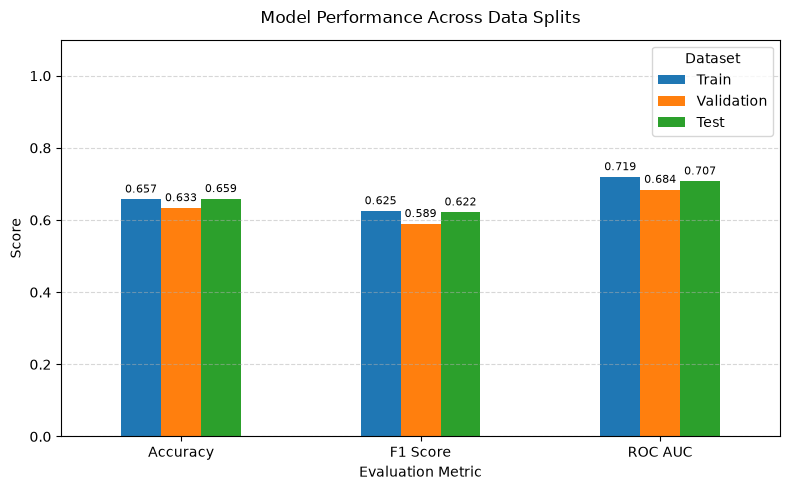

In [98]:
import pandas as pd
import matplotlib.pyplot as plt

#  Build the data frame by using the metrics
metrics_data = {
    'Metric': ['Accuracy', 'F1 Score', 'ROC AUC'],
    'Train': [train_acc, train_f1, train_auc],
    'Validation': [val_acc, val_f1, val_auc],
    'Test': [test_acc, test_f1, test_auc]
}

metrics_df = pd.DataFrame(metrics_data).set_index('Metric')

# Plot as a grouped bar chart
fig, ax = plt.subplots(figsize=(8, 5))
bars = metrics_df.plot(kind='bar', ax=ax, edgecolor='none')

# Add exact value labels on top of each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', padding=3, fontsize=8, rotation=0)

# Customise title, labels, legend, and and the limits on the y axis 
ax.set_title("Model Performance Across Data Splits", fontsize=12, pad=12)
ax.set_xlabel("Evaluation Metric", fontsize=10)
ax.set_ylabel("Score", fontsize=10)
ax.set_ylim(0, 1.1)  # slightly extended the limit to have a bit more space for the labels for each 
ax.set_xticklabels(metrics_df.index, rotation=0)
ax.legend(title="Dataset", frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

 The ROC Curves 

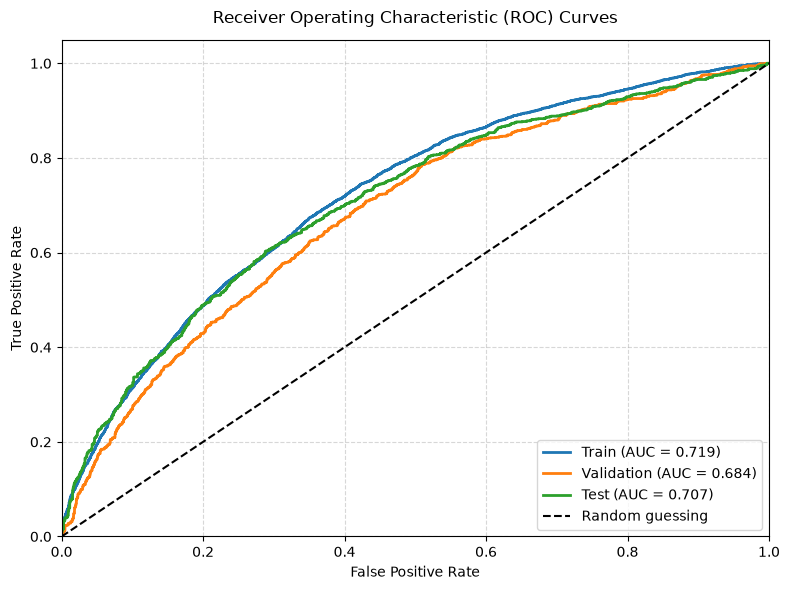

In [99]:
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt

# Calculate the false postive and the true positives for the sets 
fpr_train, tpr_train, _ = roc_curve(y_train, train_probs)
fpr_val, tpr_val, _ = roc_curve(y_val, val_probs)
fpr_test, tpr_test, _ = roc_curve(y_test, test_probs)

# Plot the ROC curves
fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(fpr_train, tpr_train, label=f"Train (AUC = {train_auc:.3f})", linewidth=2)
ax.plot(fpr_val, tpr_val, label=f"Validation (AUC = {val_auc:.3f})", linewidth=2)
ax.plot(fpr_test, tpr_test, label=f"Test (AUC = {test_auc:.3f})", linewidth=2)

# Add random guessing reference line
ax.plot([0, 1], [0, 1], 'k--', label="Random guessing", linewidth=1.5)

# Customise title, labels, limits, legend, and grid
ax.set_title("Receiver Operating Characteristic (ROC) Curves", fontsize=12, pad=12)
ax.set_xlabel("False Positive Rate", fontsize=10)
ax.set_ylabel("True Positive Rate", fontsize=10)
ax.set_xlim([0.0, 1.0])
ax.set_ylim([0.0, 1.05])
ax.legend(loc="lower right", frameon=True)
ax.grid(linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Confusion Matrix on the test set as a heat map

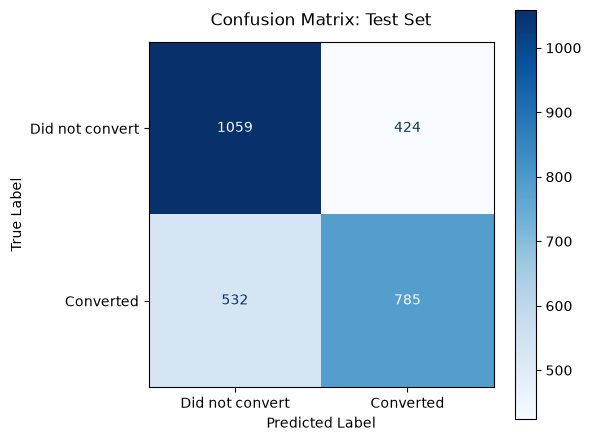

In [100]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Create a figure for the confusion matrix heatmap
fig, ax = plt.subplots(figsize=(6, 5))

# Plot the confusion matrix heatmap using the confusion matrix display
disp = ConfusionMatrixDisplay.from_predictions(
    y_test, 
    test_preds,
    display_labels=["Did not convert", "Converted"],
    cmap="Blues",
    ax=ax
)

# Customise title and labels
ax.set_title("Confusion Matrix: Test Set", fontsize=12, pad=12)
ax.set_xlabel("Predicted Label", fontsize=10)
ax.set_ylabel("True Label", fontsize=10)

plt.tight_layout()
plt.show()

## The results visualisation

# The Bar Chart
- Compared the accuracy, the F1 score and ROC AUC sisde by side across the train, validation and test data sets.
- The scores across all three sets remain very close, for example seeing accuracry sits at 0.657 for trian, 0.633 for validation and 0.659 for the test. This is an indication of the depth 5 hyperparatemete choice working well to controll overfitting.

# ROC Curves
- The ROC Curves are to evalutae how well  the modle separates converters form non converters across the different decison threshold. The AUC values were 0.719 for train and 0.684 for validationa nd 0.707 for the test.
- The curves sit well above the random guessing diagnoal line which shows that the behavioural features capture the right signal. It stays below a perfect separation which shows its a modest prediciting model.

# Confusion Matrix on the Test set 
- It shows the breakdown of the test performance into 1059 true ngeatives, 785 true positives, 424 false positives and 532 missed converters
- I noted that the erros are distributed across both classes without leaning just to either side. For StadioChoice, this would mean the model then successfully captures about 60% of actual converters, providing a balanced baseline that can be modified depending on whether the business will focus on cathcing more leads or reducing false alarms
